In [32]:
from pathlib import Path
import zipfile
from zipfile import ZipFile
import warnings 
import random

import pandas as pd 
import numpy as np

from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt 
from tqdm.auto import tqdm 
from torchinfo import summary 

import torch
from torch import nn 
import torch.functional as F 
from torch.utils.data import Dataset, DataLoader 

from torchvision import transforms
from PIL import Image

from tfrecord.reader import tfrecord_loader

warnings.filterwarnings("ignore")

In [33]:
SEED = 2026
N_SPLITS = 5
BATCH_SIZE = 64

DEV = torch.device("mps" 
if torch.backends.mps.is_available()
else "cuda"
if torch.cuda.is_available()
else "cpu")

print(f"device: {DEV}")

device: mps


In [34]:
DATA_PATH = Path("data")
FILE_PATH = DATA_PATH / "tpu-getting-started"
FILE_PATH.mkdir(parents=True, exist_ok=True)
FILE_PATH_ZIP = DATA_PATH / "tpu-getting-started.zip"

with zipfile.ZipFile(FILE_PATH_ZIP, "r") as ref_zip:
    print(f"Unzipping flowers data in {FILE_PATH} ...")
    ref_zip.extractall(FILE_PATH)

Unzipping flowers data in data/tpu-getting-started ...


In [35]:
SRC = Path("data/tpu-getting-started/tfrecords-jpeg-224x224")
DST = Path("data/flowers-224")

def convert_split(split: str, labeled: bool = True):

    out_dir = DST / split
    out_dir.mkdir(parents=True, exist_ok=True)

    description = {"image": "byte", "id": "byte"}

    if labeled:
        description["class"] = "int"

    rows = []
    for tfrec in tqdm(sorted((SRC / split).glob("*.tfrec"))):
        for rec in tfrecord_loader(str(tfrec), None, description):

            img_id = rec["id"].decode()
            (out_dir / f"{img_id}.jpg").write_bytes(rec["image"])

            row = {"id": img_id}
            if labeled:
                row["label"] = int(rec["class"][0])

            rows.append(row)

    pd.DataFrame(rows).to_csv(DST / f"{split}.csv", index=False)
    print(len(rows))

In [36]:
convert_split("train")
convert_split("val")
convert_split("test", labeled=False)

  0%|          | 0/16 [00:00<?, ?it/s]

12753


  0%|          | 0/16 [00:00<?, ?it/s]

3712


  0%|          | 0/16 [00:00<?, ?it/s]

7382


In [37]:
class FlowersDataset(Dataset):

    def __init__(self, csv_path, img_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.img_path = Path(img_path) 
        self.transform = transform
        self.has_labels = "label" in self.df.columns

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.img_path / f"{row['id']}.jpg").convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.has_labels:
            return image, torch.tensor(row["label"], dtype=torch.long)

        return image, row["id"]

In [38]:
train_tf = transforms.Compose([
    transforms.ToTensor()
])

eval_tf = transforms.Compose([
    transforms.ToTensor()
])

In [39]:
ROOT = Path("data/flowers-224")

train_ds = FlowersDataset(ROOT / "train.csv", ROOT / "train", transform=train_tf)
val_ds = FlowersDataset(ROOT / "val.csv", ROOT / "val", transform=eval_tf)
test_ds = FlowersDataset(ROOT / "test.csv", ROOT / "test", transform=eval_tf)

### Visualization data

In [40]:
def make_plots(
        data,
        rows: int=3,
        cols: int=3,
        seed=SEED):
    
    random.seed(seed)
    n = rows * cols
    random_indexes = random.sample(range(len(data)), k=n)
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))

    for ax, index in zip(axes.flatten(), random_indexes):
        img, label = data[index]
        class_name = label.item()

        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(f"Class: {class_name}", fontsize=15)
        ax.axis(False)
    plt.tight_layout()
    plt.show();

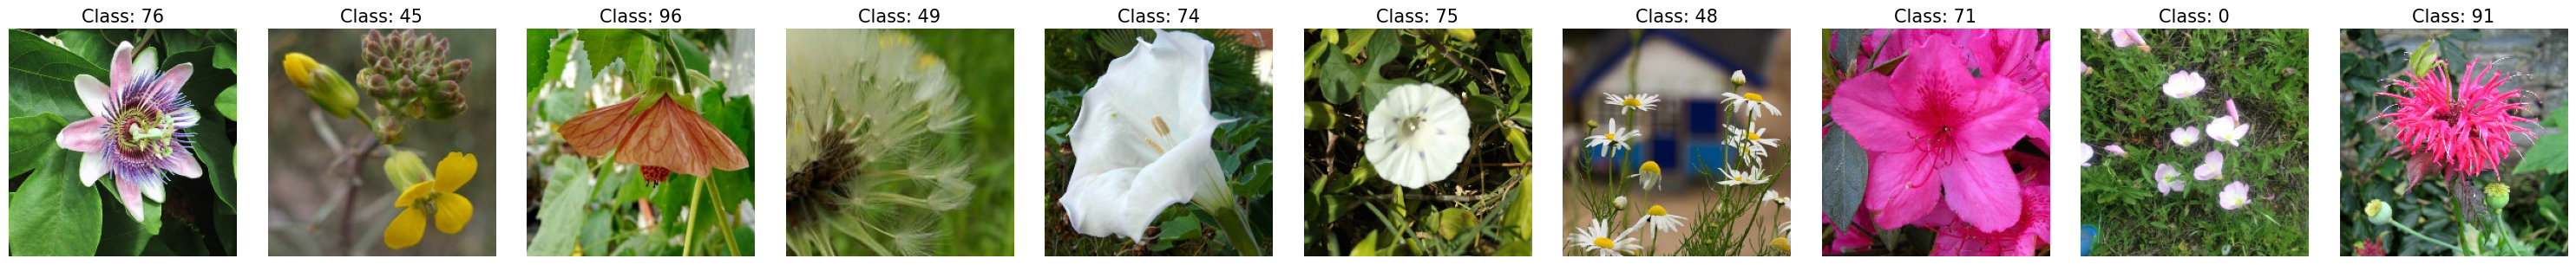

In [41]:
make_plots(train_ds, rows=1, cols=10)

In [42]:
train_loader = DataLoader(
    dataset=train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    dataset=val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    dataset=test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# for test
images, labels = next(iter(train_loader))
print(f"Shape: {images[0].shape}, \nLabel: {labels[0]}")

Shape: torch.Size([3, 224, 224]), 
Label: 74


In [67]:
classes = torch.unique(torch.tensor(train_ds.df["label"].values)).tolist()
print(f"Num classes: {len(classes)}")

Num classes: 104


In [68]:
class CustomFlowersModelv0(nn.Module):
    def __init__(self, input_shape: int, output_shape: int, hidden_units: int):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_shape, 
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units, 
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
                ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units, 
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units, 
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
                ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_features=hidden_units,
                      out_features=output_shape)
        )
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.classifier(x)
        return x